# Notebook 10 – Feature Selection
**File:** `10_Feature_Selection.ipynb`

## Learning objectives
By the end of this notebook, you will understand how to identify useful input columns, remove unnecessary information, and apply common feature-selection methods with Python.

## 1. What is Feature Selection?
Feature selection is the process of choosing a useful subset of the original input features (columns) for a Machine Learning model.

Example: To predict a house price, useful features may include area, location, and number of bedrooms. A randomly generated customer ID usually does not help predict the price.

Feature selection chooses existing columns. It is different from feature extraction, which creates new features from existing data.

## 2. Why is Feature Selection important?
It can:
- Reduce training time and computational cost.
- Make a model simpler and easier to explain.
- Reduce noise from irrelevant columns.
- Reduce overfitting in some situations.
- Sometimes improve generalization on unseen data.

**Important:** Removing features does not always improve a model. A feature that looks unimportant by itself may be useful in combination with another feature. Compare models using validation data.

## 3. Relevant, irrelevant, and redundant features

| Feature type | Meaning | Example for house-price prediction |
|---|---|---|
| Relevant | Contains useful predictive information | House area |
| Irrelevant | Has no useful relationship to the target | Random row number |
| Redundant | Repeats information already represented by another feature | Area in square feet and the same area converted to square metres |

### How unnecessary features affect Machine Learning
Irrelevant or redundant features can add noise, increase memory and training requirements, make models harder to interpret, and sometimes encourage overfitting. Redundant correlated features can also make some model coefficients unstable or make feature importance harder to interpret.

## 4. Prepare a sample dataset
We use the built-in Breast Cancer dataset from scikit-learn. It is a binary classification dataset. The target is the diagnosis class.

**Data-leakage rule:** Split the data first. Fit supervised feature-selection methods only on the training data, then transform the test data using the already-fitted selector.

In [1]:
import numpy as np
import pandas as pd
import sklearn

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")

print("Dataset shape:", X.shape)
print("Target classes:", dataset.target_names)
display(X.head())

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (455, 30)
Testing shape: (114, 30)


## 5. Correlation-Based Selection
Correlation measures the strength and direction of a linear relationship between two numeric variables. A correlation close to +1 indicates a strong positive linear relationship; close to -1 indicates a strong negative linear relationship; close to 0 indicates little linear relationship.

For input-feature screening, highly correlated pairs may contain overlapping information. Correlation does **not** prove causation, and a low correlation with the target does not prove a feature is useless because relationships can be nonlinear.

The following code finds highly correlated pairs using training data only. Review the pairs before deciding which feature to remove.

In [3]:
corr_matrix = X_train.corr(numeric_only=True).abs()

# Keep only the upper triangle to avoid showing each pair twice
upper_triangle = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

threshold = 0.90
high_corr_pairs = [
    (column, row, upper_triangle.loc[row, column])
    for column in upper_triangle.columns
    for row in upper_triangle.index
    if pd.notna(upper_triangle.loc[row, column])
    and upper_triangle.loc[row, column] > threshold
]

print(f"Highly correlated pairs (absolute correlation > {threshold}):")
for feature_1, feature_2, value in high_corr_pairs[:20]:
    print(f"{feature_1} <-> {feature_2}: {value:.3f}")

Highly correlated pairs (absolute correlation > 0.9):
mean perimeter <-> mean radius: 0.998
mean area <-> mean radius: 0.989
mean area <-> mean perimeter: 0.988
mean concave points <-> mean concavity: 0.922
perimeter error <-> radius error: 0.971
area error <-> radius error: 0.955
area error <-> perimeter error: 0.939
worst radius <-> mean radius: 0.970
worst radius <-> mean perimeter: 0.970
worst radius <-> mean area: 0.963
worst texture <-> mean texture: 0.913
worst perimeter <-> mean radius: 0.966
worst perimeter <-> mean perimeter: 0.971
worst perimeter <-> mean area: 0.959
worst perimeter <-> worst radius: 0.993
worst area <-> mean radius: 0.943
worst area <-> mean perimeter: 0.943
worst area <-> mean area: 0.957
worst area <-> worst radius: 0.986
worst area <-> worst perimeter: 0.979


## 6. Variance Threshold
Variance measures how much a feature changes. A feature with zero variance has the same value in every row and cannot distinguish observations.

`VarianceThreshold` removes features whose variance is below a chosen threshold. It does not look at the target variable. For this example, use a threshold of zero to remove only constant columns.

For binary features, variance depends on the proportion of 0s and 1s. Do not choose a large threshold without understanding the feature scale.

In [4]:
from sklearn.feature_selection import VarianceThreshold

variance_selector = VarianceThreshold(threshold=0.0)
X_train_var = variance_selector.fit_transform(X_train)
X_test_var = variance_selector.transform(X_test)

kept_by_variance = X_train.columns[variance_selector.get_support()]
removed_by_variance = X_train.columns[~variance_selector.get_support()]

print("Original feature count:", X_train.shape[1])
print("Kept feature count:", len(kept_by_variance))
print("Removed constant features:", list(removed_by_variance))

Original feature count: 30
Kept feature count: 30
Removed constant features: []


## 7. Univariate Feature Selection
Univariate methods score each feature individually against the target. They are fast and useful as an initial screening step, but they may miss interactions between features.

### SelectKBest with ANOVA F-test
`f_classif` is commonly used for numeric features and classification targets. `SelectKBest` keeps the highest-scoring `k` features.

The selector is fitted on training data only.

In [5]:
from sklearn.feature_selection import SelectKBest, f_classif

k = 10
univariate_selector = SelectKBest(score_func=f_classif, k=k)
X_train_kbest = univariate_selector.fit_transform(X_train, y_train)
X_test_kbest = univariate_selector.transform(X_test)

selected_univariate = X_train.columns[univariate_selector.get_support()]
scores = pd.Series(
    univariate_selector.scores_,
    index=X_train.columns
).sort_values(ascending=False)

print("Selected features:")
print(list(selected_univariate))
display(scores.head(15).to_frame("ANOVA F-score"))

Selected features:
['mean radius', 'mean perimeter', 'mean area', 'mean concavity', 'mean concave points', 'worst radius', 'worst perimeter', 'worst area', 'worst concavity', 'worst concave points']


,ANOVA F-score
worst concave points,795.223341
worst perimeter,719.598823
mean concave points,703.364031
worst radius,687.430367
mean perimeter,565.485755
worst area,541.713694
mean radius,523.613907
mean area,469.516453
mean concavity,416.374874
worst concavity,365.747389


## 8. Mutual Information
Mutual information estimates how much information one variable provides about another. Unlike a simple linear-correlation check, it can detect some nonlinear relationships.

A higher score suggests more information about the target. The score is not a percentage or an accuracy value. Results can vary with the data and estimator settings.

In [6]:
from sklearn.feature_selection import mutual_info_classif

mi_scores = mutual_info_classif(
    X_train, y_train, random_state=42
)
mi_series = pd.Series(
    mi_scores, index=X_train.columns
).sort_values(ascending=False)

display(mi_series.head(15).to_frame("Mutual information score"))

top_mi_features = mi_series.head(10).index.tolist()
print("Top 10 features:", top_mi_features)

,Mutual information score
worst perimeter,0.471238
worst area,0.461952
worst radius,0.458392
mean concave points,0.443749
worst concave points,0.442864
mean perimeter,0.411013
mean radius,0.364736
mean area,0.357780
mean concavity,0.353144
area error,0.337466


Top 10 features: ['worst perimeter', 'worst area', 'worst radius', 'mean concave points', 'worst concave points', 'mean perimeter', 'mean radius', 'mean area', 'mean concavity', 'area error']


## 9. Recursive Feature Elimination (RFE)
RFE repeatedly trains an estimator, ranks features, and removes the least useful feature(s) until the requested number remains.

RFE can take longer than simple filter methods. The estimator and its settings affect the selected features.

In [7]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Scaling is included because Logistic Regression is scale-sensitive.
rfe_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rfe", RFE(
        estimator=LogisticRegression(max_iter=5000, random_state=42),
        n_features_to_select=10
    ))
])

rfe_pipeline.fit(X_train, y_train)
rfe_support = rfe_pipeline.named_steps["rfe"].support_
rfe_features = X_train.columns[rfe_support].tolist()

print("Features selected by RFE:")
print(rfe_features)

Features selected by RFE:
['mean area', 'radius error', 'area error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst concavity', 'worst concave points']


## 10. Feature Importance
Tree-based models can estimate feature importance. In a Random Forest, impurity-based importance measures how much each feature contributes to reducing split impurity across the trees.

These values are useful for exploration, but they can be biased toward certain feature types and can distribute importance across correlated features. Importance is not proof of causation. Permutation importance on held-out data is another useful method.

,Random Forest importance
worst perimeter,0.150294
worst area,0.136401
mean concave points,0.106040
worst concave points,0.099206
worst radius,0.074967
mean concavity,0.058505
mean radius,0.052490
mean perimeter,0.040005
worst concavity,0.039076
mean area,0.037216


<Axes: title={'center': 'Top 15 feature importances'}>

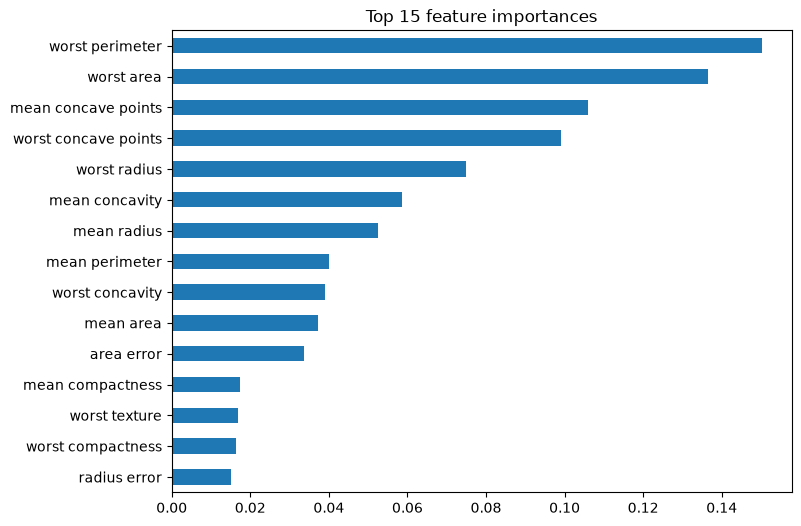

In [8]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=300, random_state=42, class_weight="balanced"
)
forest.fit(X_train, y_train)

importance = pd.Series(
    forest.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(importance.head(15).to_frame("Random Forest importance"))

importance.head(15).sort_values().plot(
    kind="barh", figsize=(8, 6), title="Top 15 feature importances"
)

## 11. Compare feature-selection approaches

| Method | Looks at target? | Main idea | Useful when |
|---|---:|---|---|
| Correlation screening | Usually no (for feature-to-feature check) | Find overlapping numeric features | Reducing redundancy |
| Variance Threshold | No | Remove near-constant features | Removing constant/low-variation columns |
| Univariate selection | Yes | Score each feature individually | Fast initial screening |
| Mutual Information | Yes | Measure information shared with target | Possible nonlinear relationships |
| RFE | Yes | Repeatedly eliminate features using a model | Model-guided selection |
| Feature importance | Yes, through fitted model | Rank features by model contribution | Understanding a fitted tree model |

## 12. Practical guidelines
1. Understand the meaning of each column before removing it.
2. Remove identifiers only when they truly do not carry useful predictive information.
3. Check duplicate or near-duplicate columns.
4. Fit supervised selectors on training data only.
5. Use cross-validation or a validation set to compare feature subsets.
6. Keep a baseline model with all appropriate features.
7. Choose features based on validation performance, simplicity, cost, and business understanding—not only a ranking score.


**Remember:** The best feature set is the one that performs reliably on unseen data while remaining understandable and practical.